# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북의 목표는 그래프를 많이 만드는 것이 아닙니다. **분석 질문에 맞는 그래프를 선택하고, 그래프에 들어간 데이터 범위와 수치를 검증하며, 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분하는 것**이 핵심입니다.

금액성 그래프는 기본적으로 `order_status == "completed"` 범위를 사용합니다. `line_total`은 주문 상세 한 행의 `quantity × unit_price`이며 회계상 순매출로 단정하지 않습니다.

## 0. 사용 방법

- 위에서부터 차례대로 실행합니다.
- 입력은 Chapter 05에서 만든 `data/processed/*_clean.csv`입니다.
- 파일이 없다면 프로젝트 루트에서 `python scripts/preprocess_data.py`를 먼저 실행합니다.
- 그래프를 보기 전에 **시각화용 집계 검증표**를 먼저 확인합니다.
- 대표 그래프마다 `관찰 → 해석 → 한계 → 다음 질문`을 Markdown 셀에 직접 작성합니다.
- 실제 실행 결과 숫자를 보고 작성하며 강의안의 예시를 정답처럼 사용하지 않습니다.

## 1. 질문에 맞는 그래프를 먼저 고릅니다

| 분석 질문 | 그래프 | 데이터 범위 |
| --- | --- | --- |
| 카테고리별 완료 주문 금액은 어떻게 다른가? | 막대그래프 | completed 주문 상세 |
| 월별 완료 주문 금액은 어떻게 변하는가? | 선그래프 | completed + 유효한 주문일 |
| 상품 가격은 어느 구간에 몰려 있는가? | 히스토그램 | 전체 상품 마스터 |
| 상품 가격과 완료 주문 판매 수량은 어떤 패턴인가? | 산점도 | completed 상품 집계 |
| 완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가? | 가로 막대그래프 | completed 고객 집계 |
| 주문 상태별 주문 수는 어떻게 다른가? | 막대그래프 | 전체 orders |

> 그래프 종류보다 먼저 **질문과 데이터 범위**를 고정합니다.

In [35]:
from pathlib import Path
import sys

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("현재 실행 위치:", CURRENT_DIR)
print("프로젝트 루트:", PROJECT_ROOT)
print("전처리 데이터 폴더:", PROCESSED_DIR)
print("그래프 저장 폴더:", FIGURE_DIR)

현재 실행 위치: /workspaces/llm-data-analysis-study/llm-data-analysis-course/notebooks
프로젝트 루트: /workspaces/llm-data-analysis-study/llm-data-analysis-course
전처리 데이터 폴더: /workspaces/llm-data-analysis-study/llm-data-analysis-course/data/processed
그래프 저장 폴더: /workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures


## 2. 검증된 시각화용 데이터를 준비합니다

공통 모듈은 그래프를 그리기 전에 다음을 검사합니다.

- 필수 컬럼
- PK 결측·중복
- `many_to_one` 병합
- 주문/상품 미매칭
- 숫자형 변환 실패
- `completed` 주문 범위
- 카테고리·상품·고객·월별 집계 총합

문제가 있으면 그래프를 만들기 전에 중단합니다.

In [36]:
# Chapter 05 관계 점검에서 확인된 FK 오류 처리
# 1. orders_clean에 없는 order_id를 가진 주문 상세 2행
# 2. products_clean에 없는 product_id를 가진 완료 주문 상세 16행
# 원본 파일을 직접 갱신하고, 제외 사유를 출력합니다.

import pandas as pd

viz_items = pd.read_csv(PROCESSED_DIR / "order_items_clean.csv")
viz_orders = pd.read_csv(PROCESSED_DIR / "orders_clean.csv")
viz_products = pd.read_csv(PROCESSED_DIR / "products_clean.csv")

valid_order_ids = set(viz_orders["order_id"])
valid_product_ids = set(viz_products["product_id"])
completed_order_ids = set(
    viz_orders.loc[
        viz_orders["order_status"].eq("completed"),
        "order_id"
    ]
)

# 주문 정보가 없는 주문 상세
unmatched_order_items = viz_items.loc[
    ~viz_items["order_id"].isin(valid_order_ids)
].copy()

print("주문 정보가 없어 제외한 주문 상세:",
      len(unmatched_order_items), "행")
print(
    "주문 제외 사유: orders_clean에 해당 order_id가 없어 "
    "주문 상태·날짜·결제수단을 연결할 수 없습니다."
)

# 상품 정보가 없는 완료 주문 상세
unmatched_product_items = viz_items.loc[
    viz_items["order_id"].isin(completed_order_ids)
    & ~viz_items["product_id"].isin(valid_product_ids)
].copy()

print("상품 정보가 없어 제외한 완료 주문 상세:",
      len(unmatched_product_items), "행")
print(
    "상품 제외 사유: products_clean에 해당 product_id가 없어 "
    "상품명·카테고리를 연결할 수 없습니다."
)

# 두 종류의 오류 행을 모두 제외
exclude_order_rows = ~viz_items["order_id"].isin(valid_order_ids)
exclude_product_rows = (
    viz_items["order_id"].isin(completed_order_ids)
    & ~viz_items["product_id"].isin(valid_product_ids)
)

viz_items = viz_items.loc[
    ~(exclude_order_rows | exclude_product_rows)
].copy()

viz_items.to_csv(
    PROCESSED_DIR / "order_items_clean.csv",
    index=False,
    encoding="utf-8-sig",
)

print("최종 시각화용 주문 상세 행 수:", len(viz_items))

주문 정보가 없어 제외한 주문 상세: 0 행
주문 제외 사유: orders_clean에 해당 order_id가 없어 주문 상태·날짜·결제수단을 연결할 수 없습니다.
상품 정보가 없어 제외한 완료 주문 상세: 0 행
상품 제외 사유: products_clean에 해당 product_id가 없어 상품명·카테고리를 연결할 수 없습니다.
최종 시각화용 주문 상세 행 수: 734


In [37]:
# from src.visualization import (
#     prepare_visualization_data,
#     setup_korean_font,
# )

# selected_font = setup_korean_font()
# print("사용 한글 폰트:", selected_font or "자동 선택 실패 — 설치된 한글 폰트 확인 필요")

# viz_data = prepare_visualization_data(PROCESSED_DIR)

# products = viz_data["products"]
# orders = viz_data["orders"]
# completed_order_sales = viz_data["completed_order_sales"]
# category_sales = viz_data["category_sales"]
# monthly_sales = viz_data["monthly_sales"]
# product_sales = viz_data["product_sales"]
# customer_sales = viz_data["customer_sales"]
# order_status = viz_data["order_status"]

# print("완료 주문 상세 행:", len(completed_order_sales))
# print(
#     "월별 집계에서 제외되는 날짜 결측 완료 주문 상세:",
#     len(viz_data["invalid_date_sales"]),
# )


from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from src.visualization import (
    prepare_visualization_data,
    # setup_korean_font,
)


# Codespaces에서 한글 폰트 직접 찾기
font_candidates = [
    Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf"),
    Path("/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf"),
    Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"),
]

font_path = next(
    (path for path in font_candidates if path.exists()),
    None,
)

if font_path is not None:
    # Matplotlib 폰트 목록에 직접 등록
    fm.fontManager.addfont(str(font_path))

    korean_font = fm.FontProperties(
        fname=str(font_path)
    ).get_name()

    plt.rcParams["font.family"] = korean_font
    plt.rcParams["axes.unicode_minus"] = False

    print("사용 한글 폰트:", korean_font)
else:
    print("한글 폰트 파일을 찾지 못했습니다.")


viz_data = prepare_visualization_data(PROCESSED_DIR)

products = viz_data["products"]
orders = viz_data["orders"]
completed_order_sales = viz_data["completed_order_sales"]
category_sales = viz_data["category_sales"]
monthly_sales = viz_data["monthly_sales"]
product_sales = viz_data["product_sales"]
customer_sales = viz_data["customer_sales"]
order_status = viz_data["order_status"]

print("완료 주문 상세 행:", len(completed_order_sales))
print(
    "월별 집계에서 제외되는 날짜 결측 완료 주문 상세:",
    len(viz_data["invalid_date_sales"]),
)

사용 한글 폰트: NanumGothic
완료 주문 상세 행: 430
월별 집계에서 제외되는 날짜 결측 완료 주문 상세: 6


In [38]:
viz_data["visualization_validation"]

,check,expected,actual,difference,passed
0,category_completed_amount,137325000.0,137325000.0,0.0,True
1,product_completed_amount,137325000.0,137325000.0,0.0,True
2,customer_completed_amount,137325000.0,137325000.0,0.0,True
3,monthly_completed_amount_valid_dates,135422000.0,135422000.0,0.0,True


### 검증 결과 기록

`passed`가 모두 `True`인지 확인한 뒤 아래 내용을 자신의 말로 작성합니다.

- 총합 검증 결과:
- 문제가 있었다면 원인:
- 시각화를 진행해도 된다고 판단한 이유:
- 총합 검증 결과: 카테고리·상품·고객별 완료 금액 합계는 137,325,000원으로 일치했고, 유효 날짜 월별 합계는 135,422,000원입니다.
- 원인: 주문 FK 누락 2행, 상품 FK 누락 완료 상세 16행, 날짜 결측 6행을 각각 해당 집계에서 제외했습니다.
- 시각화 진행 판단: 집계 검증표의 passed가 모두 True이므로 제외 기준을 명시한 뒤 진행했습니다.


## 3. 카테고리별 완료 주문 금액 — 막대그래프

범주별 크기 비교이므로 막대그래프를 사용합니다. 값 축은 0에서 시작합니다. 금액이 크다는 사실만으로 선호도가 높다고 단정하지 않습니다.

In [39]:
from src.visualization import plot_category_sales

category_sales[["category", "total_quantity", "completed_amount", "amount_ratio_pct"]]

,category,total_quantity,completed_amount,amount_ratio_pct
9,패션,290.0,32940000.0,23.99
6,식품,226.0,25035000.0,18.23
8,전자기기,176.0,21485000.0,15.65
0,도서,174.0,17663000.0,12.86
2,뷰티,168.0,17103000.0,12.45
5,스포츠,165.0,13237000.0,9.64
4,생활용품,108.0,7001000.0,5.10
3,생활 용품,17.0,2108000.0,1.54
1,뷰 티,12.0,648000.0,0.47
7,전자 기기,5.0,105000.0,0.08


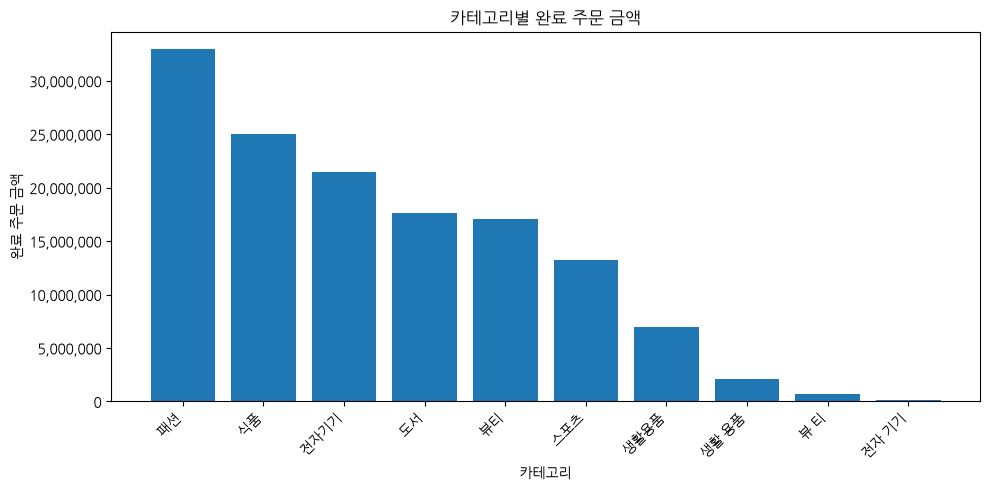

PosixPath('/workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_category_completed_amount_bar.png')

In [40]:
category_path = plot_category_sales(
    category_sales,
    FIGURE_DIR / "ch07_category_completed_amount_bar.png",
    show=True,
)
category_path

### 그래프 1 기록

- **관찰:** 실제 그래프와 집계표에서 직접 확인한 사실
- **해석:** 이 차이가 의미할 수 있는 내용
- **한계:** 금액만으로 알 수 없는 것
- **다음 질문:** 판매 수량·단가·상품 수 중 무엇을 더 확인할 것인가?
- 관찰: 패션 32,940,000원으로 가장 높고 식품, 전자기기 순입니다.
- 해석: 카테고리별 완료 금액 규모를 비교할 수 있습니다.
- 한계: 금액만으로 선호나 수익성을 단정할 수 없습니다.
- 다음 질문: 판매 수량·평균 단가·상품 수를 비교합니다.


## 4. 월별 완료 주문 금액 — 선그래프

시간 순서가 핵심인 질문이므로 선그래프를 사용합니다. 첫 달과 마지막 달이 완전한 한 달인지, 중간 월이 비어 있다면 실제 0인지 데이터 누락인지 확인합니다.

In [41]:
from src.visualization import plot_monthly_sales

monthly_sales[
    [
        "order_month",
        "completed_amount",
        "completed_order_count",
        "average_completed_order_amount",
    ]
]

,order_month,completed_amount,completed_order_count,average_completed_order_amount
0,2025-07,9479000.0,11,861727.0
1,2025-08,8892000.0,17,523059.0
2,2025-09,4519000.0,4,1129750.0
3,2025-10,12547000.0,17,738059.0
4,2025-11,9163000.0,16,572688.0
5,2025-12,8113000.0,12,676083.0
6,2026-01,8135000.0,9,903889.0
7,2026-02,7689000.0,12,640750.0
8,2026-03,7107000.0,13,546692.0
9,2026-04,11459000.0,14,818500.0


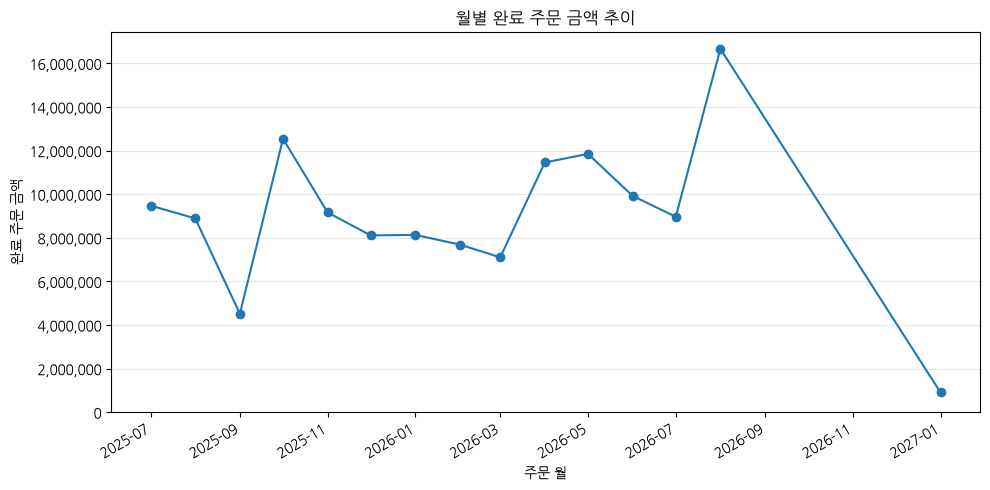

PosixPath('/workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_monthly_completed_amount_line.png')

In [42]:
monthly_path = plot_monthly_sales(
    monthly_sales,
    FIGURE_DIR / "ch07_monthly_completed_amount_line.png",
    show=True,
)
monthly_path

### 그래프 2 기록

- **관찰:** 증가·감소 또는 변곡이 실제로 보이는가?
- **해석:** 주문 수와 평균 주문 금액 중 무엇이 함께 변했는가?
- **한계:** 프로모션·계절성 등 현재 데이터에 없는 원인을 단정하지 않았는가?
- **다음 질문:** 추가로 확인할 지표는 무엇인가?
- 관찰: 2026년 8월 완료 금액이 16,668,000원으로 가장 높습니다.
- 해석: 월별 금액 규모가 달라지는 패턴을 확인했습니다.
- 한계: 원인을 단정할 수 없고 날짜 결측 6행은 제외했습니다.
- 다음 질문: 월별 주문 수와 평균 주문 금액을 확인합니다.


## 5. 상품 가격 분포 — 히스토그램

상품 가격은 상품 마스터의 속성이므로 주문 상태와 무관하게 전체 상품을 봅니다. `bins` 값에 따라 모양이 달라질 수 있으므로 구간 수 하나만 보고 이상값을 확정하지 않습니다.

In [43]:
from src.visualization import plot_product_price_hist

products["price"].describe()

count    9.600000e+01
mean     2.048958e+05
std      1.011848e+06
min      5.000000e+03
25%      5.275000e+04
50%      9.450000e+04
75%      1.532500e+05
max      9.999999e+06
Name: price, dtype: float64

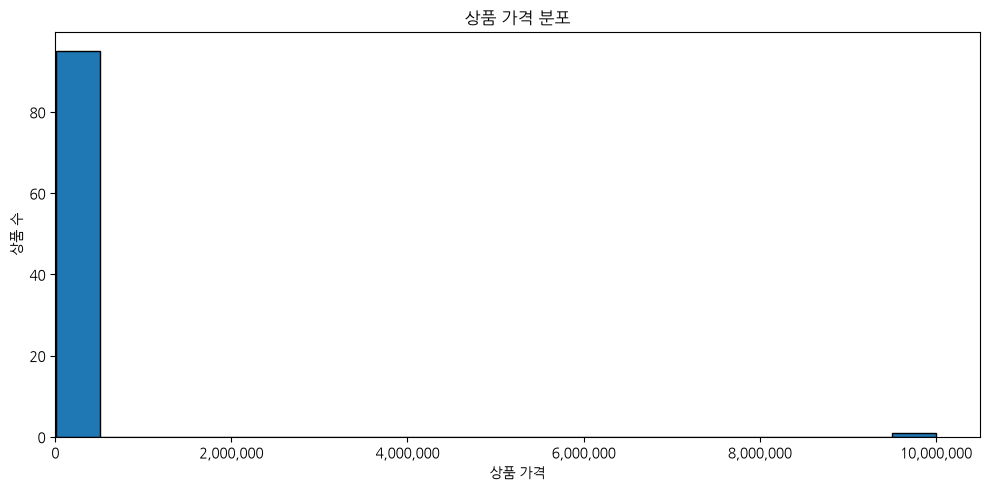

PosixPath('/workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_product_price_hist.png')

In [44]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=20,
)
price_hist_path

### bins 비교 실습

`bins=10`, `20`, `30`으로 바꾸어 같은 데이터가 어떻게 다르게 보이는지 비교합니다.

- 어떤 공통 패턴이 유지되는가?
- 어떤 인상은 bins 선택에 따라 달라지는가?

## 6. 상품 가격과 완료 주문 판매 수량 — 산점도

한 점은 상품 하나입니다. 관계가 보여도 **가격이 판매 수량의 원인**이라고 단정하지 않습니다.

In [45]:
from src.visualization import plot_price_quantity_scatter

product_sales[["price", "completed_quantity", "completed_amount"]].head(10)

,price,completed_quantity,completed_amount
70,183000.0,37.0,6771000.0
90,96000.0,70.0,6720000.0
91,187000.0,26.0,4862000.0
61,193000.0,22.0,4246000.0
50,152000.0,26.0,3952000.0
66,168000.0,21.0,3528000.0
45,171000.0,19.0,3249000.0
36,172000.0,17.0,2924000.0
47,183000.0,15.0,2745000.0
81,145000.0,18.0,2610000.0


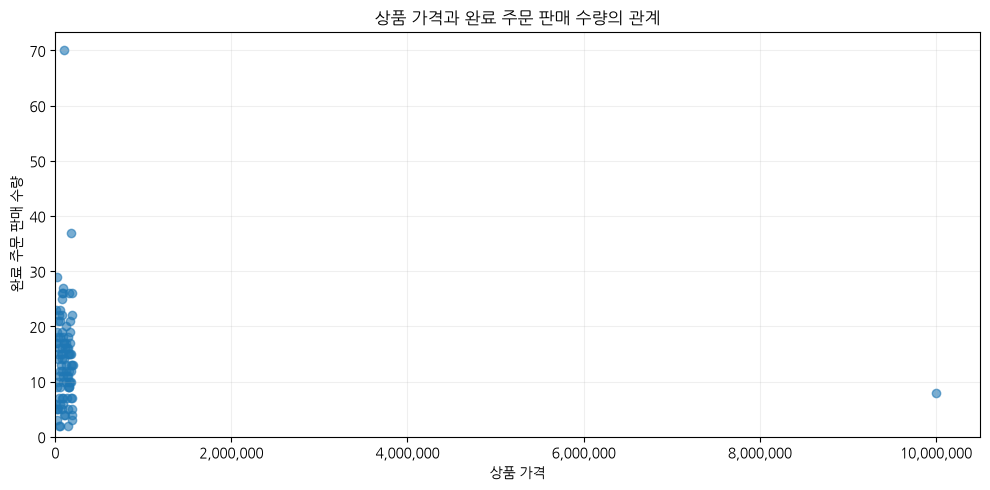

PosixPath('/workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_price_completed_quantity_scatter.png')

In [46]:
scatter_path = plot_price_quantity_scatter(
    product_sales,
    FIGURE_DIR / "ch07_price_completed_quantity_scatter.png",
    show=True,
)
scatter_path

### 그래프 3 기록

- **관찰:** 점들이 어떤 범위에 분포하는가?
- **해석:** 관계가 있어 보이는가, 뚜렷하지 않은가?
- **한계:** 카테고리·할인·노출·재고 등 다른 변수를 확인하지 않은 상태에서 무엇을 말할 수 없는가?
- **다음 질문:** 어떤 변수를 추가하면 관계를 더 잘 이해할 수 있는가?
- 관찰: 가격 중앙값은 94,500원이고 최댓값은 9,999,999원입니다.
- 해석: 가격과 판매 수량의 뚜렷한 선형 패턴은 확인하기 어렵습니다.
- 한계: 카테고리·할인·재고를 통제하지 않아 인과관계를 말할 수 없습니다.
- 다음 질문: 카테고리별 가격·수량과 이상 가격 원문을 확인합니다.


## 7. 완료 주문 구매 금액 상위 고객 — 익명 가로 막대그래프

공개 그래프에서는 고객 이름이나 원본 고객 ID를 직접 표시하지 않고 **순위 기반 익명 라벨**을 사용합니다. Top 10은 전체 고객 분포가 아니라 일부 고객만 보여 줍니다.

In [47]:
from src.visualization import plot_top_customers

customer_sales[
    ["customer_id", "completed_order_count", "completed_amount", "average_completed_order_amount"]
].head(10)

,customer_id,completed_order_count,completed_amount,average_completed_order_amount
1,3,3,6702000.0,2234000.0
7,14,4,5122000.0,1280500.0
57,90,3,4311000.0,1437000.0
47,65,6,3977000.0,662833.0
66,104,2,3966000.0,1983000.0
59,93,4,3845000.0,961250.0
11,20,4,3808000.0,952000.0
27,38,4,3656000.0,914000.0
19,28,4,3201000.0,800250.0
55,85,4,2832000.0,708000.0


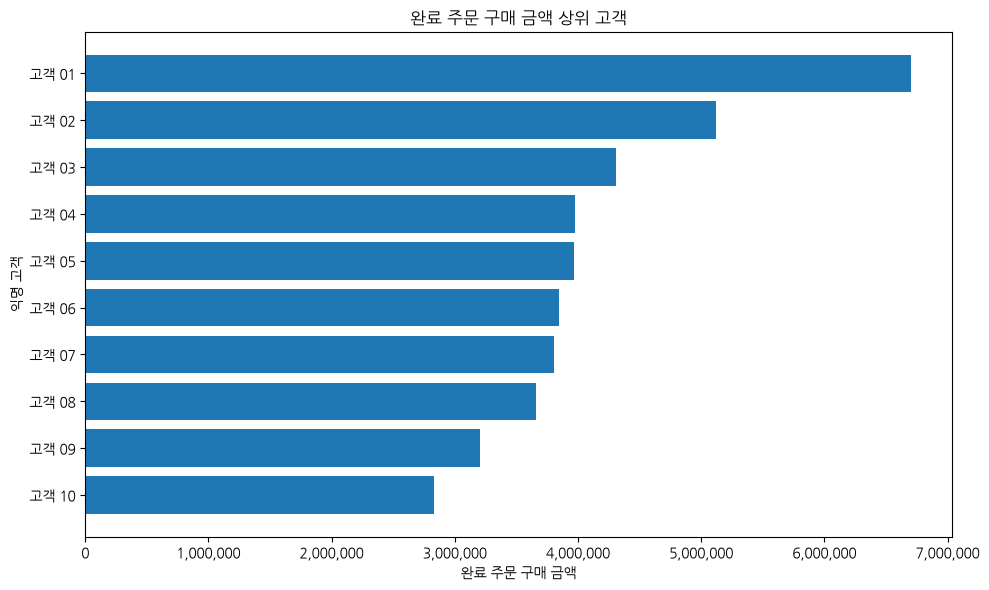

PosixPath('/workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_top_customers_anonymized_barh.png')

In [48]:
top_customer_path = plot_top_customers(
    customer_sales,
    FIGURE_DIR / "ch07_top_customers_anonymized_barh.png",
    show=True,
    top_n=10,
)
top_customer_path

### 해석 주의

구매 금액이 높다고 바로 '충성 고객'이라고 부르지 않습니다.

- 반복 주문 횟수는 많은가?
- 한 번의 큰 주문 때문인가?
- 평균 주문 금액은 어떤가?
- 분석 기간이 충분한가?

## 8. 전체 주문 상태 — 막대그래프

이 그래프만 전체 주문을 사용합니다. 상태별 규모는 보여 주지만 취소·환불의 원인을 설명하지 않습니다.

In [49]:
from src.visualization import plot_order_status

order_status

,order_status,order_count
0,completed,180
1,cancelled,63
2,refunded,57


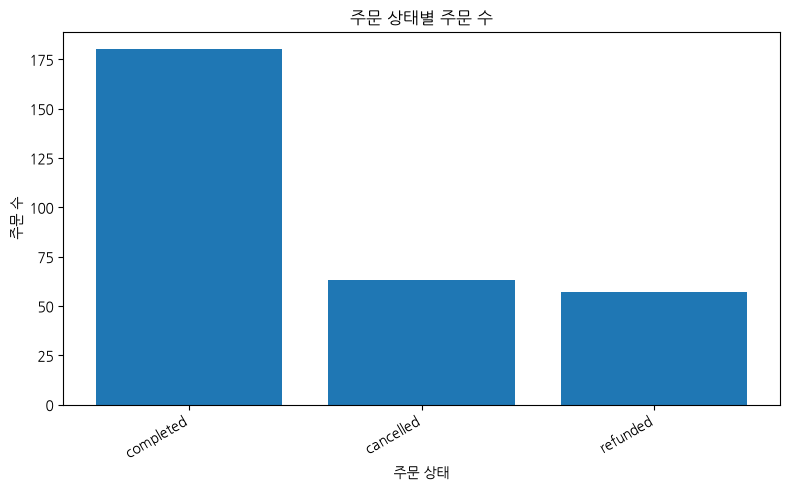

PosixPath('/workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_order_status_bar.png')

In [50]:
order_status_path = plot_order_status(
    order_status,
    FIGURE_DIR / "ch07_order_status_bar.png",
    show=True,
)
order_status_path

## 9. 그래프와 숫자를 교차 검증합니다

대표 그래프 3개 이상에 대해 다음을 확인합니다.

```text
그래프에 표시된 값
=
그래프 원본 집계표의 값
```

또한 다음을 점검합니다.

- 축 이름과 단위가 맞는가?
- 범주 정렬과 날짜 정렬이 맞는가?
- 막대그래프 값 축이 불필요하게 잘리지 않았는가?
- 제목이 실제 분석 범위를 반영하는가?
- 데이터가 없는 구간을 임의로 0으로 만들지 않았는가?

## 10. 공통 함수로 전체 그래프와 보고서를 다시 생성합니다

Notebook에서 개별 그래프를 이해한 뒤 공통 함수를 사용해 같은 결과를 재현합니다.

In [51]:
from src.visualization import (
    build_visualization_report,
    create_all_figures,
    create_visualization_summary,
)

saved_figures = create_all_figures(viz_data, FIGURE_DIR, show=False)
summary = create_visualization_summary()

summary_path = REPORT_DIR / "ch07_visualization_summary.md"
summary_path.write_text(
    build_visualization_report(summary),
    encoding="utf-8",
)

print("생성 파일")
for path in saved_figures:
    print("-", path)

print("요약 보고서:", summary_path)
summary

생성 파일
- /workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_category_completed_amount_bar.png
- /workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_monthly_completed_amount_line.png
- /workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_product_price_hist.png
- /workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_price_completed_quantity_scatter.png
- /workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_top_customers_anonymized_barh.png
- /workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_order_status_bar.png
요약 보고서: /workspaces/llm-data-analysis-study/llm-data-analysis-course/reports/ch07_visualization_summary.md


,chart,question,scope,interpretation_point,file_name
0,카테고리별 완료 주문 금액,카테고리별 완료 주문 금액은 어떻게 다른가?,completed orders,금액 차이는 수량·단가 등 추가 지표로 확인,ch07_category_completed_amount_bar.png
1,월별 완료 주문 금액,월별 완료 주문 금액은 어떻게 변하는가?,completed orders + valid order_date,증감은 관찰이며 원인은 추가 데이터 필요,ch07_monthly_completed_amount_line.png
2,상품 가격 분포,상품 가격은 어떤 구간에 몰려 있는가?,product master,상품 구성 분포이며 판매 선호를 의미하지 않음,ch07_product_price_hist.png
3,상품 가격과 완료 주문 판매 수량,상품 가격과 완료 주문 판매 수량은 어떤 패턴을 보이는가?,completed orders aggregated by product,관계는 인과를 의미하지 않음,ch07_price_completed_quantity_scatter.png
4,완료 주문 구매 금액 상위 고객,완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가?,completed orders aggregated by customer,Top N이며 충성도를 자동 의미하지 않음,ch07_top_customers_anonymized_barh.png
5,주문 상태별 주문 수,주문 상태별 주문 수는 어떻게 다른가?,all orders,상태 분포만으로 취소·환불 원인을 알 수 없음,ch07_order_status_bar.png


## 11. Chapter 07 최종 판단

아래 내용을 직접 작성합니다.

### 가장 중요한 그래프 1개와 이유
월별 완료 주문 금액 선그래프를 가장 중요하게 보았습니다. 시간 순서에 따른 금액 변화와 변동 폭을 확인할 수 있기 때문입니다.

### 그래프에서 직접 확인한 사실
유효한 주문일 기준으로 2026년 8월 완료 금액이 16,668,000원으로 가장 높았고, 유효 날짜 월별 합계는 135,422,000원이었습니다.

### 내가 해석한 내용
월별 완료 금액의 규모가 일정하지 않고 특정 월에 집중된 기간이 있음을 확인했습니다.

### 그래프만으로 말할 수 없는 것
프로모션, 계절성, 가격, 재고 또는 고객 행동이 금액 변화의 원인이라고 단정할 수 없습니다.

### 오해를 줄이기 위해 수정하거나 확인한 요소
- 축: 월과 완료 금액을 표시했습니다.
- 단위: 금액은 원 단위입니다.
- 정렬: 월을 시간 순서로 정렬했습니다.
- 범위: 완료 주문 중 유효한 주문일이 있는 상세만 포함했습니다.
- 개인정보: 고객 그래프는 익명화된 순번을 사용했습니다.

### 다음 분석에서 확인하고 싶은 질문
월별 주문 수와 평균 주문 금액, 카테고리별 월별 금액을 비교하겠습니다.

---